In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Building Dataframe #


In [4]:
# reading csv files into dataframes
cat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
print('Sample Size of SAMI Input Catalogue Dataset:', len(cat))
print(cat.columns)
    # "Mstar","dex","Logarithm of stellar mass","phys.mass"

kin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')
print('Sample Size of SAMI Stellar Kinematics Dataset:', len(kin))
print(kin.columns)
    # "SIGMA_RE","km/s","Velocity dispersion from Re Sersic aperture spectra","phys.veloc.dispersion"

morph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
print('Sample Size of SAMI Visual Morphology Dataset:', len(morph))
print(morph.columns)
    # "TYPE","none","Morphological Type 

Sample Size of SAMI Input Catalogue Dataset: 1433
Index(['Unnamed: 0', 'catid', 'ra_obj', 'dec_obj', 'r_petro', 'r_auto',
       'z_spec', 'm_r', 'r_e', 'mu_within_1re', 'mu_1re', 'mu_2re', 'ellip',
       'pa', 'g_i', 'mstar', 'r_on_rtwo', 'v_on_sigma', 'is_mem', 'surv_sami',
       'bad_class'],
      dtype='object')
Sample Size of SAMI Stellar Kinematics Dataset: 3426
Index(['Unnamed: 0', 'cubeid', 'cubeidpub', 'cubename', 'catid', 'pa_stelkin',
       'pa_stelkin_err', 'sigma_re', 'sigma_re_err', 'sigma_3kpc_round',
       'sigma_3kpc_round_err', 'sigma_1_4_arcsecond',
       'sigma_1_4_arcsecond_err', 'sigma_2_arcsecond', 'sigma_2_arcsecond_err',
       'sigma_3_arcsecond', 'sigma_3_arcsecond_err', 'sigma_4_arcsecond',
       'sigma_4_arcsecond_err', 'aper_corr_flag', 'rmax_aper_corr',
       'lambdar_re', 'lambdar_re_err', 'lambdar_max', 'lambdar_max_err',
       'vsigma_re', 'vsigma_re_err', 'vsigma_max', 'vsigma_max_err',
       'mean_k51_re', 'mean_k51_re_err', 'sigma_re_mge',

In [5]:
mass = cat[['catid', 'mstar','mu_1re', 'bad_class']]
print('Sample Size of Mass Dataset:\n', mass.head(20))
vdisp = kin[['catid', 'sigma_re']]
print('Sample Size of Velocity Dispersion Dataset:\n', vdisp)
type = morph[['catid', 'type']]
print('Sample Size of Morphology Dataset:\n', type)

Sample Size of Mass Dataset:
          catid      mstar     mu_1re  bad_class
0   9011900001  11.587700  24.425760          0
1   9011900002  10.157130  20.176815          8
2   9011900003  10.205531        NaN          0
3   9011900005   9.887663        NaN          0
4   9011900006  10.841409  20.363825          0
5   9011900007   9.530834  26.682870          0
6   9011900008  10.474614  20.680416          8
7   9011900009  10.533861  20.665499          0
8   9011900011  10.014269  23.869879          0
9   9011900012   9.969811  24.497694          0
10  9011900013  10.376080  20.405502          0
11  9011900014   9.794188  23.306000          0
12  9011900017   9.575955  21.590899          0
13  9011900019   9.553915  20.377289          0
14  9011900020   9.501628  22.748575          0
15  9011900024  11.460869  22.202436          0
16  9011900025   9.805207  21.600061          0
17  9011900026  10.112734  22.227749          0
18  9011900027  10.948296  21.441301          0
19  901190

In [6]:
morphcat = pd.merge(morph, mass, on='catid', how='inner')
df = pd.merge(morphcat, vdisp, on='catid', how='inner')
print('Final Data Set', len(df))
print(df.head(20))

Final Data Set 962
    Unnamed: 0       catid  type      mstar     mu_1re  bad_class    sigma_re
0         2151  9008500001   0.0  11.733240  22.194613          0         NaN
1         2152  9008500002   0.0  11.733201  22.220806          0         NaN
2         2153  9008500004   1.5  10.639072  26.886974          0         NaN
3         2154  9008500007   0.0  10.939993  20.561842          0  265.057370
4         2154  9008500007   0.0  10.939993  20.561842          0         NaN
5         2155  9008500018   0.5  10.028619  20.182903          0  130.505040
6         2156  9008500020   0.0  10.894950  22.480024          0  170.477860
7         2157  9008500022   0.5  10.140078  21.249514          0   98.179590
8         2158  9008500024   0.5  10.753547  20.904030          0  187.108870
9         2159  9008500034   1.0  10.199323  20.802740          0  143.926180
10        2160  9008500042   0.0  10.522638  20.710413          0  202.322860
11        2161  9008500043   3.0   9.631680  

In [7]:
elliptical = df[df['type'] == 0.0] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical))
print('Elliptical Galaxies:\n', elliptical.head(20))

# Columns are just misaligned, there are mstar and sigma_re values

Number of Elliptical Galaxies: 152
Elliptical Galaxies:
     Unnamed: 0       catid  type      mstar     mu_1re  bad_class    sigma_re
0         2151  9008500001   0.0  11.733240  22.194613          0         NaN
1         2152  9008500002   0.0  11.733201  22.220806          0         NaN
3         2154  9008500007   0.0  10.939993  20.561842          0  265.057370
4         2154  9008500007   0.0  10.939993  20.561842          0         NaN
6         2156  9008500020   0.0  10.894950  22.480024          0  170.477860
10        2160  9008500042   0.0  10.522638  20.710413          0  202.322860
12        2162  9008500059   0.0  10.612209  22.171244          0  204.846340
14        2164  9008500064   0.0  10.014470  21.802141          0  125.197975
16        2166  9008500068   0.0  10.189114  21.571623          8   87.443590
20        2170  9008500077   0.0  10.764045  22.191960          0  183.164600
27        2177  9008500096   0.0  10.905760  22.008698          0  164.250000
34     

# Cleaning Data #

In [8]:
df_clean_elliptical = elliptical.dropna(subset = ['mstar', 'sigma_re', 'mu_1re'])
good_elliptical = df_clean_elliptical[df_clean_elliptical['bad_class'] == 0]

print('Cleaned Data Set', len(df_clean_elliptical))
print('Good Elliptical Galaxies', len(good_elliptical))
print(good_elliptical.head(20))

Cleaned Data Set 107
Good Elliptical Galaxies 106
     Unnamed: 0       catid  type      mstar     mu_1re  bad_class    sigma_re
3          2154  9008500007   0.0  10.939993  20.561842          0  265.057370
6          2156  9008500020   0.0  10.894950  22.480024          0  170.477860
10         2160  9008500042   0.0  10.522638  20.710413          0  202.322860
12         2162  9008500059   0.0  10.612209  22.171244          0  204.846340
14         2164  9008500064   0.0  10.014470  21.802141          0  125.197975
20         2170  9008500077   0.0  10.764045  22.191960          0  183.164600
27         2177  9008500096   0.0  10.905760  22.008698          0  164.250000
36         2186  9008500118   0.0  10.358594  22.136293          0  122.640700
44         2194  9008500138   0.0  10.378108  20.584938          0  114.042900
45         2195  9008500139   0.0  10.479002  21.034206          0  131.962300
52         2202  9008500169   0.0  10.709361  21.824500          0  173.848070
57

# Plotting Mass against Velocity Dispersion #

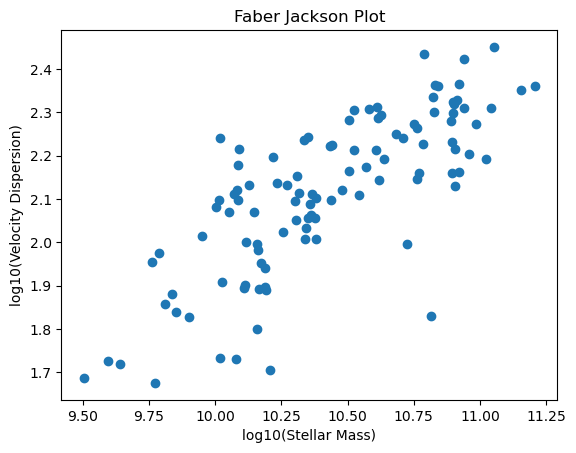

In [13]:
#plt.scatter(df_clean_elliptical['mstar'], np.log10(df_clean_elliptical['sigma_re']))
#plt.title('Faber Jackson Plot')
#plt.xlabel('log10(Stellar Mass)')
#plt.ylabel('log10(Velocity Dispersion)')

#m0, b0 = np.polyfit(df_clean_elliptical['mstar'], np.log10(df_clean_elliptical['sigma_re']), 1)

#plt.plot(df_clean_elliptical['mstar'], m0 * df_clean_elliptical['mstar'] + b0, color="red", label=f"Best Fit 0: y={m0:.2f}x+{b0:.2f}")

#plt.legend()

#plt.show()

In [10]:
r = df_clean_elliptical['mstar'].corr(df_clean_elliptical['sigma_re'])
print("Correlation coefficient, r, between Stellar Mass and Velocity Dispersion for Elliptical Galaxies: ", r)


Correlation coefficient, r, between Stellar Mass and Velocity Dispersion for Elliptical Galaxies:  0.7768210578113118


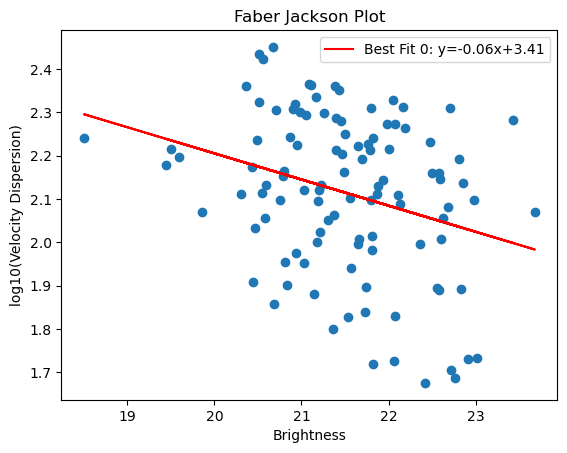

In [11]:
plt.scatter(df_clean_elliptical['mu_1re'], np.log10(df_clean_elliptical['sigma_re']))
plt.title('Faber Jackson Plot')
plt.xlabel('Brightness')
plt.ylabel('log10(Velocity Dispersion)')

m0, b0 = np.polyfit(df_clean_elliptical['mu_1re'], np.log10(df_clean_elliptical['sigma_re']), 1)

plt.plot(df_clean_elliptical['mu_1re'], m0 * df_clean_elliptical['mu_1re'] + b0, color="red", label=f"Best Fit 0: y={m0:.2f}x+{b0:.2f}")

plt.legend()

#plt.show()